# Praktikum Data Mining – Evaluasi Model Klasifikasi
## Tugas 3 – Evaluasi Data Tidak Seimbang
Kelompok 7 Data Mining

Anggota: Lutfiah Sahira (24343039), Imam Atthahira (24343037) , Rangga Dharma Putra (24343045). Mata kuliah: Data Mining· Dosen pengampu: Dr. Yeka Hendriyani, S.Kom., M.Kom. Program Studi Informatika, Departemen Teknik Elektronika, Fakultas Teknik, Universitas Negeri Padang


### Persiapan (data, model, dan prediksi dari langkah sebelumnya)

In [1]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(42)
n = 500
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)
score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)
prob = 1/(1+np.exp(-score))
isFraud = rng.binomial(1, prob)
df = pd.DataFrame({'amount':amount.round(2), 'hour':hour,
                   'new_device':new_device, 'foreign_ip':foreign_ip,
                   'isFraud':isFraud})

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
X = df.drop(columns='isFraud')
y = df['isFraud']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, classification_report)

baseline = np.zeros(len(y_test), dtype=int)

### Sel T3

                Model  Accuracy  Precision  Recall    F1
Baseline semua normal     0.967      0.000     0.0 0.000
        Decision Tree     0.767      0.059     0.4 0.103


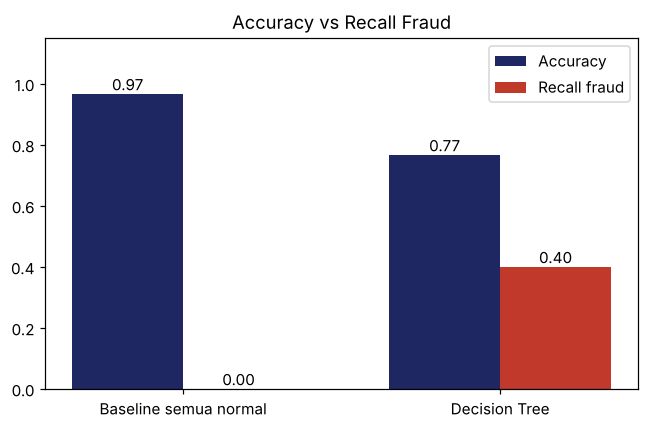

In [2]:
rows = []
for nama, p in [('Baseline semua normal', baseline), ('Decision Tree', y_pred)]:
    rows.append([nama, accuracy_score(y_test, p), precision_score(y_test, p, zero_division=0),
                 recall_score(y_test, p, zero_division=0), f1_score(y_test, p, zero_division=0)])
ringkas = pd.DataFrame(rows, columns=['Model','Accuracy','Precision','Recall','F1'])
print(ringkas.round(3).to_string(index=False))
plt.figure(figsize=(6, 4))
xs = np.arange(2); w = 0.35
b1 = plt.bar(xs - w/2, ringkas['Accuracy'], w, label='Accuracy', color='#1E2761')
b2 = plt.bar(xs + w/2, ringkas['Recall'], w, label='Recall fraud', color='#C0392B')
plt.bar_label(b1, fmt='%.2f'); plt.bar_label(b2, fmt='%.2f')
plt.xticks(xs, ringkas['Model']); plt.ylim(0, 1.15); plt.legend()
plt.title('Accuracy vs Recall Fraud'); plt.tight_layout()
plt.savefig('fig_baseline.png', dpi=150); plt.show()